# 02 – Distributions and Outliers

**Objective:** analyse the distribution of the target (`price`) and of the main numerical and categorical features, detect outliers and erroneous extreme values, and decide how to treat them before modelling.

**Input:** `data/processed/listings_00.parquet` (output of notebook 00).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df = pd.read_parquet("../data/processed/listings_00.parquet")
df.shape

(23109, 78)

In [2]:
main_num_cols = ["price", "accommodates", "bedrooms", "beds", "bathrooms",
                 "minimum_nights", "maximum_nights", "number_of_reviews",
                 "review_scores_rating", "availability_365"]

df[main_num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
price,18785.0,208.632525,543.628283,9.13,95.45,151.00,224.50,36883.0
accommodates,23109.0,3.256913,1.934129,1.00,2.00,3.00,4.00,16.0
bedrooms,23097.0,1.396848,1.031847,0.00,1.00,1.00,2.00,50.0
beds,22535.0,2.039405,2.065032,1.00,1.00,2.00,2.00,167.0
bathrooms,23091.0,1.307479,0.741310,0.00,1.00,1.00,1.50,19.0
minimum_nights,21380.0,8.873901,26.244603,1.00,1.00,2.00,5.00,1125.0
maximum_nights,21380.0,585.105519,424.502033,1.00,365.00,365.00,1125.00,11111.0
number_of_reviews,23109.0,65.981436,111.763542,0.00,2.00,22.00,80.00,1600.0
review_scores_rating,19294.0,4.640686,0.480326,0.00,4.55,4.75,4.91,5.0
availability_365,23109.0,159.547319,136.263132,0.00,1.00,151.00,298.00,365.0


## 1. Target variable: `price`

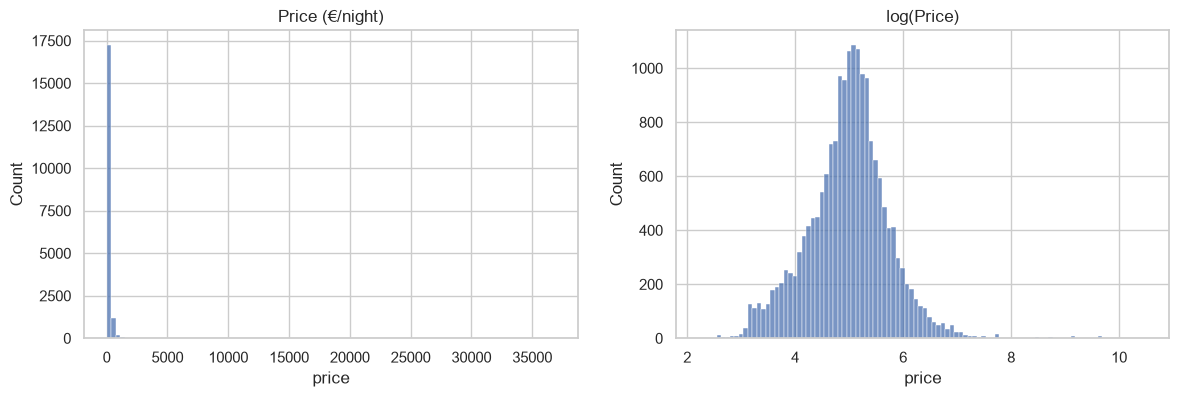

Skewness price:      31.54
Skewness log(price): 0.21


In [3]:
price = df["price"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(price, bins=100, ax=axes[0])
axes[0].set_title("Price (€/night)")
sns.histplot(np.log(price), bins=100, ax=axes[1])
axes[1].set_title("log(Price)")
plt.show()

print(f"Skewness price:      {price.skew():.2f}")
print(f"Skewness log(price): {np.log(price).skew():.2f}")

The raw price is extremely right-skewed (skewness ≈ 31.5): most listings cost less than 250 €/night, but a few reach tens of thousands. After a log transformation the distribution becomes almost symmetric (skewness ≈ 0.2). **Conclusion:** the model should predict `log(price)` instead of `price`, and outliers should be evaluated on the log scale.

In [4]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

low, high = iqr_bounds(price)
n_out = ((price < low) | (price > high)).sum()
print(f"IQR on price:      [{low:.1f}, {high:.1f}] €  -> {n_out} outliers ({n_out/len(price):.1%})")

log_price = np.log(price)
log_low, log_high = iqr_bounds(log_price)
n_out_log = ((log_price < log_low) | (log_price > log_high)).sum()
print(f"IQR on log(price): [{np.exp(log_low):.1f}, {np.exp(log_high):.1f}] €  -> {n_out_log} outliers ({n_out_log/len(price):.1%})")

IQR on price:      [-98.1, 418.1] €  -> 1219 outliers (6.5%)
IQR on log(price): [26.5, 809.8] €  -> 609 outliers (3.2%)


In [5]:
extreme = df[df["price"] >= 5000]
print(f"{len(extreme)} listings with price >= 5,000 €/night")
print(extreme["host_id"].value_counts().head(3))

extreme[["price", "host_id", "room_type", "accommodates",
         "number_of_reviews", "availability_365"]].sort_values("price", ascending=False)

28 listings with price >= 5,000 €/night
host_id
17011402     11
712177646    10
137289804     1
Name: count, dtype: int64


,price,host_id,room_type,accommodates,number_of_reviews,availability_365
6046,36883.00,17011402,Entire home/apt,6,2,351
17978,15000.00,712177646,Entire home/apt,4,0,365
18025,15000.00,712177646,Entire home/apt,4,0,365
18024,15000.00,712177646,Entire home/apt,3,0,365
17986,15000.00,712177646,Private room,2,0,364
17983,15000.00,712177646,Private room,3,0,365
17981,15000.00,712177646,Private room,2,0,365
17980,15000.00,712177646,Private room,2,0,365
17979,15000.00,712177646,Entire home/apt,4,0,365
17827,15000.00,712177646,Entire home/apt,7,0,365


In [6]:
log_low3, log_high3 = iqr_bounds(log_price, k=3)
upper_price = np.exp(log_high3)
print(f"Extreme-outlier threshold (3·IQR on log scale): {upper_price:.0f} €/night")

n_before = len(df)
df = df[~(df["price"] > upper_price)]
print(f"Removed {n_before - len(df)} listings with price > {upper_price:.0f} €/night")
df.shape

Extreme-outlier threshold (3·IQR on log scale): 2921 €/night
Removed 38 listings with price > 2921 €/night


(23071, 78)

### Decision on price outliers

- **Extreme values are errors, not luxury listings.** The 28 listings above 5,000 €/night are mostly ordinary flats and private rooms; 21 of them belong to just two hosts (one with 11 listings at exactly 15,000 €), almost none have reviews and most are available all year. These look like placeholder prices used to block bookings.
- **Action 1 – remove extreme outliers:** listings above the extreme-outlier fence (Q3 + 3·IQR on the log scale ≈ 2,921 €/night) are removed: **38 listings (0.2% of priced listings)**. This is an objective rule, not an arbitrary cut-off.
- **Action 2 – keep moderate outliers:** the 1.5·IQR rule on the log scale flags 609 listings (26.5–810 €/night), mostly cheap private/shared rooms and large or luxury flats. These are plausible prices and represent real market segments, so they are kept. Modelling `log(price)` will limit their influence.
- Applying the IQR rule to the raw price is not appropriate: it flags 6.5% of listings and gives a negative lower bound.